## 在S形数据上训练简单的去噪扩散模型

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

### 1. 准备数据

shape of s: (10240, 2)


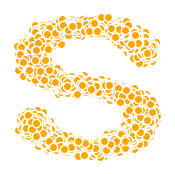

In [2]:
from sklearn.datasets import make_s_curve

s_curve, t = make_s_curve(10240, noise=0.1)
s_curve = s_curve[:,[0,2]] / 10.0  # 每个点取第0维和第2维, 再除以10
print("shape of s:", np.shape(s_curve))

data = s_curve.T
fig,ax = plt.subplots(figsize=(2, 2))
ax.scatter(*data, color='orange',edgecolor='white')
ax.axis('off')

dataset = torch.Tensor(s_curve).float()

演示原始数据分布加噪20步后的结果，可观察到S曲线逐渐变为高斯分布的过程：

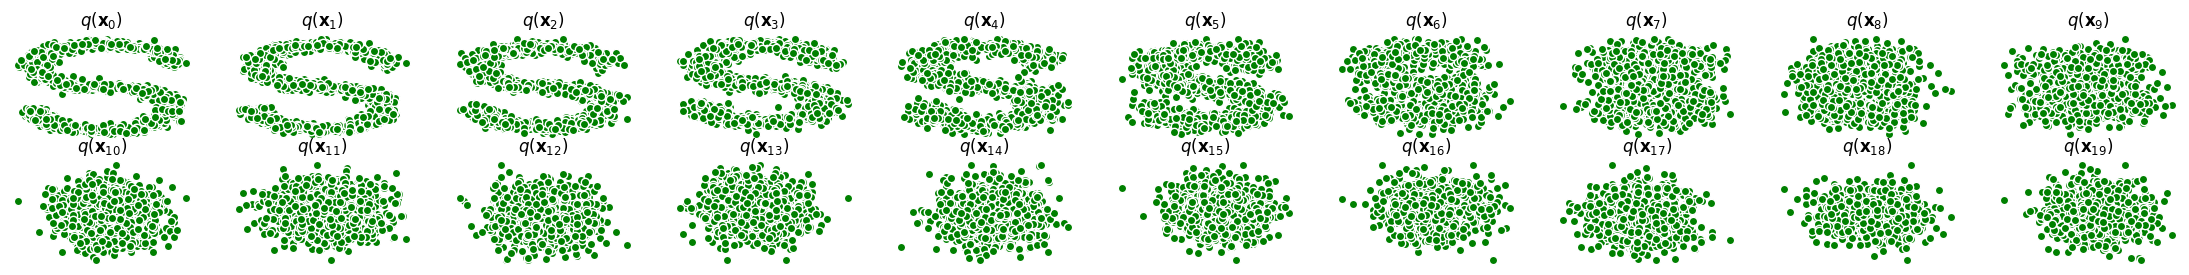

In [3]:
from ddpm import DDPM
n_steps = 20
ddpm = DDPM(n_steps)
x_0 = dataset[::10]  # 每10个点取一个点作为初始数据

fig, axes = plt.subplots(2, 10, figsize=(28,3))
plt.rc('text',color='black')
for t in range(n_steps):
    ax = axes[t//10, t%10]
    x_t, _ = ddpm.forward_step(dataset[::10], torch.tensor([t]))
    ax.scatter(x_t[:,0], x_t[:,1], color='green', edgecolor='white')
    ax.set_axis_off()
    ax.set_title('$q(\mathbf{x}_{'+str(t)+'})$')

### 搭建去噪网络

MLP denosing network

In [4]:
class MLPDenosingBlock(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.dim_in = dim_in
        self.dim_out = dim_out
        
        self.linear = nn.Linear(dim_in, dim_out)
        self.fn = nn.ReLU()

    def forward(self, x, t_emb):
        x = self.linear(x)
        x = x + t_emb # 在线性映射和激活函数中间插入时间条件
        x = self.fn(x)
        return x

class MLPDenosing(nn.Module):
    def __init__(self, n_steps, dim=128):
        super().__init__()
        self.dim = dim
        self.layers = nn.ModuleList(
            [
                MLPDenosingBlock(2, dim),
                MLPDenosingBlock(dim, dim),  
                MLPDenosingBlock(dim, dim),  
            ]
        )
        self.out_proj = nn.Linear(dim, 2)
        self.time_emb = nn.Embedding(n_steps, dim)
        
    def forward(self, x, t):
        # ndim对齐
        t_emb = self.time_emb(t).reshape(-1, self.dim)
        for block in self.layers:
            x = block(x, t_emb)       
        x = self.out_proj(x)
        return x

### DDPM
> Denoising Diffusion Probabilistic Models (https://arxiv.org/abs/2006.11239)

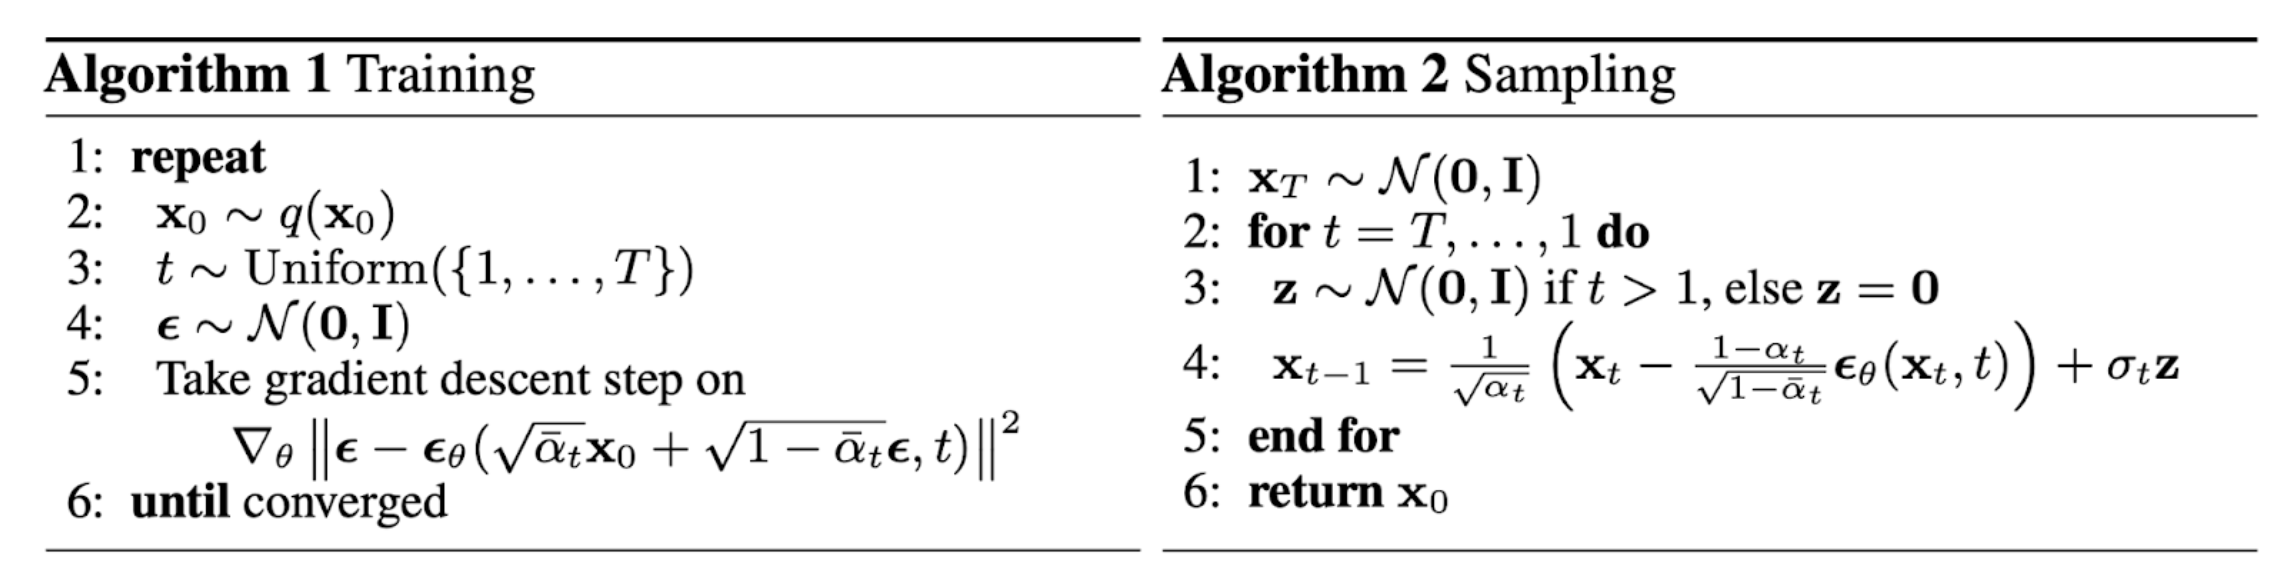

### 训练

In [ ]:
batch_size = 1024
num_epoch = 4000
num_steps = 100
dim = 128

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ddpm = DDPM(num_steps, device)
model = MLPDenosing(num_steps, dim).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) 
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

for epoch in range(num_epoch):
    for x in dataloader:
        x = x.to(device)
        t = torch.randint(0, num_steps, size=(x.size(0), 1), device=device)
        x_t, noise = ddpm.forward_step(x, t)
        # 损失计算
        loss = F.mse_loss(model(x_t, t), noise)  # 预测噪声
        
        optimizer.zero_grad()  # 梯度清零
        loss.backward()  # 损失回传
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.)  # 梯度裁剪
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 500 == 0:
        print(f'Epoch {epoch + 1}/{num_epoch}, Loss: {loss.item():.4f}')

Epoch 1/4000, Loss: 1.0272
Epoch 500/4000, Loss: 0.3774
Epoch 1000/4000, Loss: 0.3833
Epoch 1500/4000, Loss: 0.4180
Epoch 2000/4000, Loss: 0.3557
Epoch 2500/4000, Loss: 0.3352
Epoch 3000/4000, Loss: 0.3588
Epoch 3500/4000, Loss: 0.3254
Epoch 4000/4000, Loss: 0.3497


### 推理

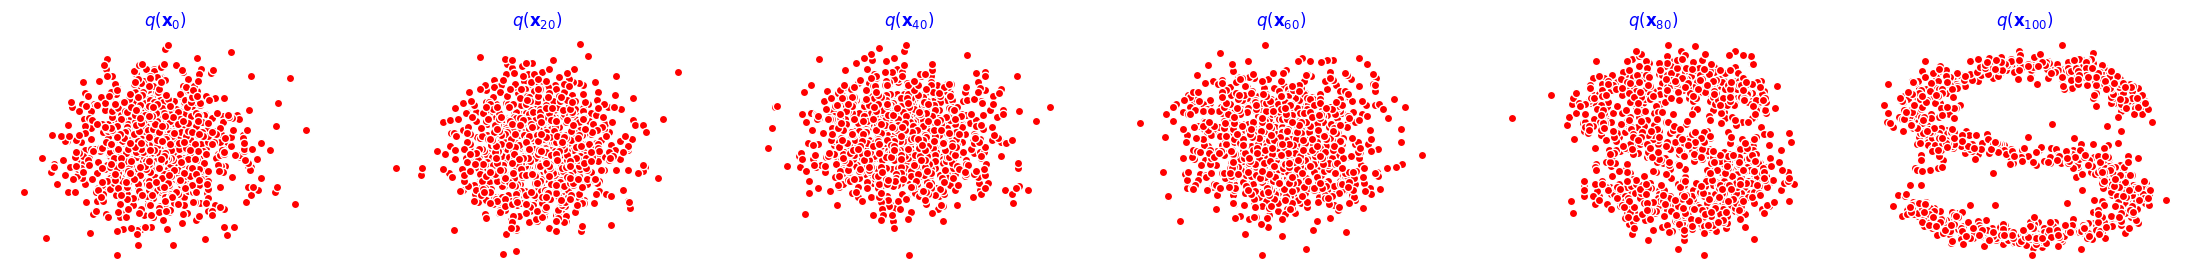

In [ ]:
model.eval()
with torch.inference_mode():
    x_t = torch.randn_like(dataset[::10].to(device))  # 使用初始数据
    x_seq = [x_t.cpu()]
    for i in reversed(range(num_steps)):
        t = torch.tensor([i] * x_t.size(0), device=device)
        eps = model(x_t, t)
        x_t = ddpm.reverse_step(x_t, eps, t)  # 逐步去噪
        x_seq.append(x_t.cpu())

# plot picture
plt.rc('text',color='blue')
x_seq = x_seq[::20]
fig, axs = plt.subplots(1, len(x_seq), figsize=(28,3))
for i, cur_x in enumerate(x_seq):
    cur_x = cur_x.cpu()
    axs[i].scatter(cur_x[:,0],cur_x[:,1],color='red',edgecolor='white');
    axs[i].set_axis_off();
    axs[i].set_title('$q(\mathbf{x}_{'+str(i*20)+'})$')